# Scania APS: cost-sensitive fault classification

**DS605 — Fundamentals of Machine Learning**  
Lakshita Pagaria (202618052) · Ameya Trivedi (202618047)

This notebook is the executable research companion to the deployment code.
It imports the same preprocessing, training and metric implementations used
by the app. It distinguishes APS-related from non-APS-related failures;
a negative result is not proof that a vehicle is healthy.

**Cost:** 10 × false positives + 500 × false negatives.
Full regeneration writes a new `runs/` directory and preserves the shipped
`artifacts/` release. The official benchmark test has already been observed
during development; fresh fleet generalization needs external validation.


In [1]:
from pathlib import Path
import sys
import os
import json
import hashlib
import subprocess
from datetime import datetime, timezone
import uuid
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / 'aps_pipeline.py').is_file()
             and (p / 'artifacts/manifest.json').is_file()), None)
if ROOT is None:
    raise RuntimeError('Open this notebook from the extracted repository or its notebooks directory.')
sys.path.insert(0, str(ROOT))
from train import load_uci
from metrics import report, cost_row, select_threshold
from service import load_release, parse_upload, score_batch, digest
from sklearn.model_selection import train_test_split

DATA = ROOT / 'dataset/raw_data'
TRAIN = DATA / 'aps_failure_training_set.csv'
TEST = DATA / 'aps_failure_test_set.csv'
if not TRAIN.is_file() or not TEST.is_file():
    raise FileNotFoundError('Place the two original UCI CSVs in dataset/raw_data/.')
print('Repository located. Python:', sys.version.split()[0])


Repository located. Python: 3.12.10


## 1. Reproducible run settings

Both flags default to `True`: Run All retrains the complete pipeline, runs the
course experiments and verifies the result. For a faster read-only review,
set both to `False` to inspect the shipped outputs. This is an explicit mode
choice, not a silent fallback. The approved application release is unchanged.


In [2]:
REBUILD_RELEASE = True
REBUILD_EXPERIMENTS = True
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '-' + uuid.uuid4().hex[:6]
RUN = ROOT / 'runs' / RUN_ID
RUN.mkdir(parents=True, exist_ok=False)
RELEASE = RUN / 'artifacts' if REBUILD_RELEASE else ROOT / 'artifacts'
RESEARCH = RUN / 'experiment-results' if REBUILD_EXPERIMENTS else ROOT / 'experiment-results'

def run_module(filename, arguments):
    completed = subprocess.run([sys.executable, str(ROOT / filename), *map(str, arguments)],
                               cwd=ROOT, text=True, capture_output=True)
    (RUN / (filename + '.stdout.log')).write_text(completed.stdout, encoding='utf-8')
    (RUN / (filename + '.stderr.log')).write_text(completed.stderr, encoding='utf-8')
    if completed.stdout:
        print(completed.stdout)
    if completed.stderr:
        print('Runtime messages recorded in runs/' + RUN_ID + '/' + filename + '.stderr.log')
    if completed.returncode:
        raise RuntimeError(filename + ' failed:\n' + completed.stderr)
print('Run:', RUN_ID)


Run: 20261114T145522Z-c46313


## 2. Ingestion and label audit

`load_uci` skips the 20-line UCI preamble, maps `na` to missing, validates the
170 raw sensor columns and maps `neg → 0`, `pos → 1`. Input validation rejects
invalid numbers and entirely unobserved records rather than making up values.
Only the training file is opened during development and threshold selection.


,label,count
0,non-APS-related,59000
1,APS-related,1000


Training records/features: (60000, 170)
Negative/positive ratio: 59.0


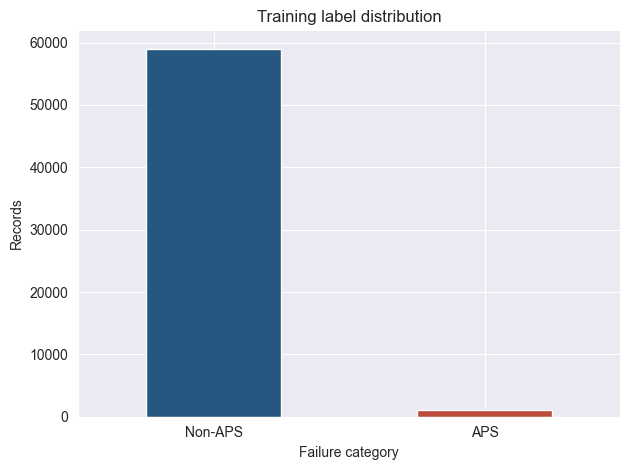

In [3]:
X, y = load_uci(TRAIN)
counts = y.value_counts().sort_index()
display(pd.DataFrame({'label': ['non-APS-related', 'APS-related'], 'count': counts.to_numpy()}))
print('Training records/features:', X.shape)
print('Negative/positive ratio:', round(counts[0] / counts[1], 2))
ax = counts.rename(index={0: 'Non-APS', 1: 'APS'}).plot.bar(rot=0, color=['#255780', '#bc4c3c'])
ax.set(xlabel='Failure category', ylabel='Records', title='Training label distribution')
plt.tight_layout(); plt.show()


## 3. Raw-data exploration

Sensors are anonymous. Distributions and missingness support statistical
feature design, but do not establish names such as compressor pressure,
physical failure mechanisms, or a forecast horizon.


,missing_fraction
br_000,0.821067
bq_000,0.812033
bp_000,0.795667
bo_000,0.772217
ab_000,0.772150
cr_000,0.772150
bn_000,0.733483
bm_000,0.659150
bl_000,0.454617
bk_000,0.383900


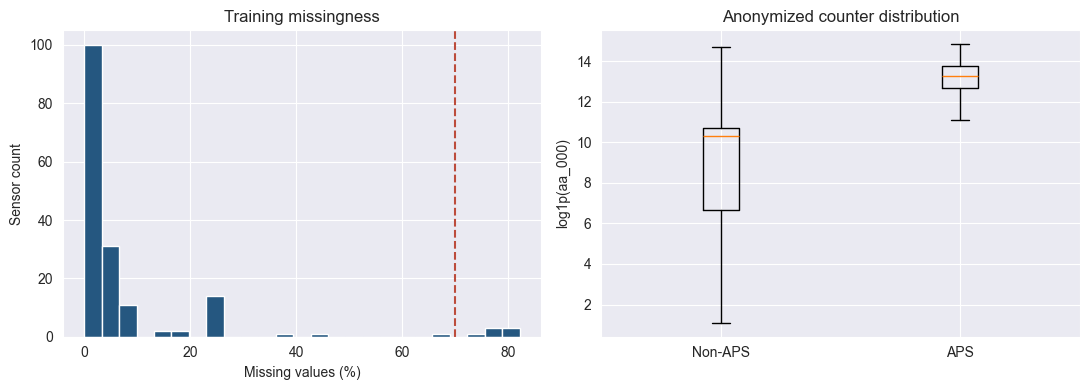

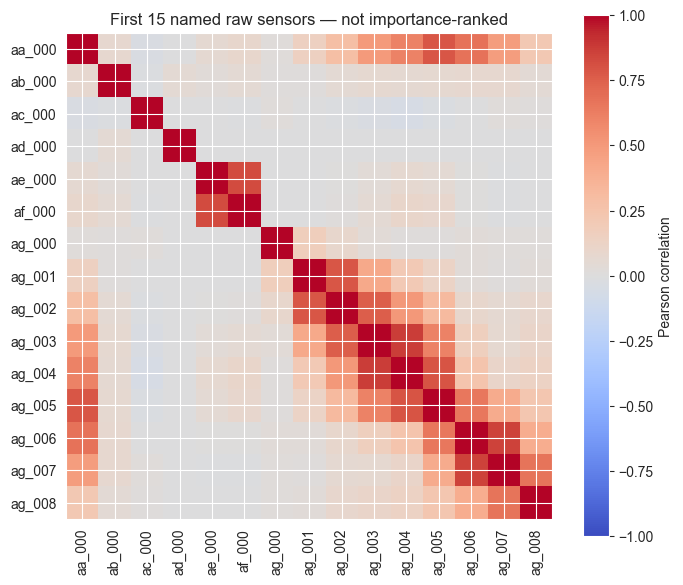

In [4]:
missing = X.isna().mean().sort_values(ascending=False)
display(missing.head(12).rename('missing_fraction').to_frame())
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(missing * 100, bins=25, color='#255780')
axes[0].axvline(70, linestyle='--', color='#bc4c3c')
axes[0].set(xlabel='Missing values (%)', ylabel='Sensor count', title='Training missingness')
axes[1].boxplot([np.log1p(X.loc[y == label, 'aa_000'].dropna()) for label in [0, 1]],
                tick_labels=['Non-APS', 'APS'], showfliers=False)
axes[1].set(ylabel='log1p(aa_000)', title='Anonymized counter distribution')
fig.tight_layout(); plt.show()
correlations = X.iloc[:, :15].corr()
fig, ax = plt.subplots(figsize=(7, 6))
mesh = ax.imshow(correlations, vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(15), correlations.columns, rotation=90)
ax.set_yticks(range(15), correlations.columns)
ax.set_title('First 15 named raw sensors — not importance-ranked')
fig.colorbar(mesh, ax=ax, label='Pearson correlation')
fig.tight_layout(); plt.show()


## 4. Split first, fit second

The stratified 85/15 split is made on raw records. Missingness selection,
imputation, variance filtering and scaling are fitted on the fit partition.
Row-wise feature engineering uses no cross-record statistics. Validation
records only pass through `transform`. The cost/threshold policy is frozen
before opening the official test in the training script.


In [5]:
X_fit, X_val, y_fit, y_val = train_test_split(X, y, test_size=.15, stratify=y, random_state=42)
assert set(X_fit.index).isdisjoint(set(X_val.index))
display(pd.DataFrame({'partition': ['fit', 'validation'],
                      'rows': [len(X_fit), len(X_val)],
                      'APS positives': [int(y_fit.sum()), int(y_val.sum())]}))


,partition,rows,APS positives
0,fit,51000,850
1,validation,9000,150


## 5. Train and export the complete production pipeline

This cell calls `train.py`; it does not reimplement the estimator. The shared
pipeline performs feature engineering → training-only pruning → median
imputation → variance selection → RobustScaler → balanced-subsample RF.
PCA is **not** part of RF inference; it is examined in the research branch.
An all-missing histogram remains unknown until imputation (`min_count=1`).


In [6]:
if REBUILD_RELEASE:
    run_module('train.py', ['--train', TRAIN, '--test', TEST, '--out', RELEASE])
model, meta, validation = load_release(RELEASE)
display(model)
print('Recorded fit/validation rows:', meta['fit_rows'], meta['validation_rows'])
print('Score type:', meta['score_kind'])
assert digest(TRAIN) == meta['training_data_sha256']
assert digest(TEST) == meta['test_data_sha256']


Fitting full pipeline on 51000 rows
Validation threshold fixed: 0.11
{
  "validation_selected": {
    "threshold": 0.11,
    "tn": 8699,
    "fp": 151,
    "fn": 6,
    "tp": 144,
    "cost": 4510,
    "roc_auc": 0.9920591337099811,
    "average_precision": 0.8363809949499588,
    "recall": 0.96,
    "precision": 0.488135593220339,
    "f1": 0.647191011235955
  },
  "test_selected": {
    "threshold": 0.11,
    "tn": 15393,
    "fp": 232,
    "fn": 28,
    "tp": 347,
    "cost": 16320,
    "roc_auc": 0.9933397333333334,
    "average_precision": 0.8817975028955924,
    "recall": 0.9253333333333333,
    "precision": 0.5993091537132987,
    "f1": 0.7274633123689728
  },
  "test_default_050": {
    "threshold": 0.5,
    "tn": 15611,
    "fp": 14,
    "fn": 153,
    "tp": 222,
    "cost": 76640,
    "roc_auc": 0.9933397333333334,
    "average_precision": 0.8817975028955924,
    "recall": 0.592,
    "precision": 0.940677966101695,
    "f1": 0.7266775777414075
  },
  "test_always_negative": {

Pipeline(steps=[('features', FeatureEngineer()),
                ('missingness', MissingnessPruner()),
                ('imputer', SimpleImputer(strategy='median')),
                ('variance', VarianceThreshold()), ('scaler', RobustScaler()),
                ('model',
                 RandomForestClassifier(class_weight='balanced_subsample',
                                        n_jobs=1, random_state=42))])

Recorded fit/validation rows: 51000 9000
Score type: uncalibrated model score


## 6. Manual leakage and preprocessing cross-checks

We recompute pruning and medians from the fit rows and compare them with the
loaded production transformers. Validation transformation must not change
these fitted statistics. This checks training ownership of learned state.


In [7]:
features = model.named_steps['features']
prune = model.named_steps['missingness']
imputer = model.named_steps['imputer']
enriched_fit = features.transform(X_fit)
expected_columns = enriched_fit.columns[enriched_fit.isna().mean() <= .70].tolist()
assert expected_columns == prune.columns_
np.testing.assert_allclose(enriched_fit[expected_columns].median().to_numpy(), imputer.statistics_)
before = imputer.statistics_.copy()
val_scores = model.predict_proba(X_val)[:, 1]
np.testing.assert_array_equal(before, imputer.statistics_)
np.testing.assert_allclose(val_scores, validation.score.to_numpy(), rtol=1e-12, atol=1e-12)
assert model.named_steps['model'].n_features_in_ == model.named_steps['variance'].get_support().sum()
display(pd.DataFrame({'stage': ['raw', 'engineered', 'after missingness pruning', 'after constant removal'],
                      'features': [X.shape[1], enriched_fit.shape[1], len(prune.columns_),
                                   int(model.named_steps['variance'].get_support().sum())]}))
print('Fit-owned preprocessing and frozen validation-score checks passed.')


,stage,features
0,raw,170
1,engineered,186
2,after missingness pruning,179
3,after constant removal,178


Fit-owned preprocessing and frozen validation-score checks passed.


## 7. Cost-sensitive decision threshold

Select the cutoff from exact validation scores, keeping tied scores together.
This is empirical cost-sensitive tuning. For a calibrated deployment posterior
with zero loss on correct decisions, the theoretical loss-based cutoff would
be `10/(10+500)`. Our RF outputs are uncalibrated scores, so we do not substitute
that theoretical posterior cutoff or invent a probability floor.


,threshold,tn,fp,fn,tp,cost
selected validation policy,0.11,8699,151,6,144,4510
default 0.50,0.50,8835,15,58,92,29150


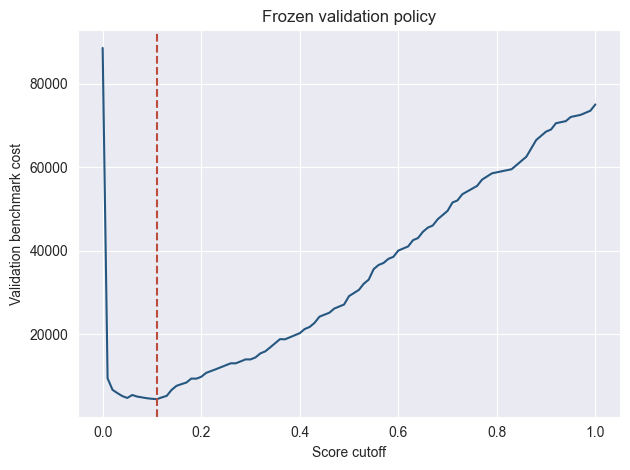

In [8]:
threshold, curve = select_threshold(y_val, val_scores)
assert threshold == meta['threshold']
display(pd.DataFrame([cost_row(y_val, val_scores, threshold), cost_row(y_val, val_scores, .5)],
                     index=['selected validation policy', 'default 0.50']))
ax = curve.plot(x='threshold', y='cost', legend=False, color='#255780')
ax.axvline(threshold, color='#bc4c3c', linestyle='--')
ax.set(xlabel='Score cutoff', ylabel='Validation benchmark cost', title='Frozen validation policy')
plt.tight_layout(); plt.show()


## 8. Frozen official-test evaluation

These results describe the same model/threshold pair loaded by the app.
We do not pick a better-looking cutoff from the test set. A lower benchmark
loss versus 0.50 does not establish realized annual fleet savings.


In [9]:
X_test, y_test = load_uci(TEST)
test_scores = model.predict_proba(X_test)[:, 1]
actual = report(y_test, test_scores, threshold)
for key, expected in meta['metrics']['test_selected'].items():
    np.testing.assert_allclose(actual[key], expected, rtol=1e-12, atol=1e-12)
display(pd.DataFrame(meta['metrics']).T)
print('Full-test metric reproduction passed for', len(X_test), 'records.')
print('Measured benchmark loss reduction versus 0.50: {:.2%}'.format(
    1 - actual['cost'] / meta['metrics']['test_default_050']['cost']))


,threshold,tn,fp,fn,tp,cost,roc_auc,average_precision,recall,precision,f1
validation_selected,0.11,8699.0,151.0,6.0,144.0,4510.0,0.992059,0.836381,0.960000,0.488136,0.647191
test_selected,0.11,15393.0,232.0,28.0,347.0,16320.0,0.993340,0.881798,0.925333,0.599309,0.727463
test_default_050,0.50,15611.0,14.0,153.0,222.0,76640.0,0.993340,0.881798,0.592000,0.940678,0.726678
test_always_negative,1.00,15625.0,0.0,375.0,0.0,187500.0,NaN,NaN,NaN,NaN,NaN
test_always_positive,0.00,0.0,15625.0,0.0,375.0,156250.0,NaN,NaN,NaN,NaN,NaN


Full-test metric reproduction passed for 16000 records.
Measured benchmark loss reduction versus 0.50: 78.71%


## 9. Supervised comparisons, PCA and imbalance mitigation

`experiments.py` uses only the original training file and the same raw split.
It actually trains balanced RF/HGB, balanced log-PCA LR, SMOTE log-PCA LR
and undersampled log-PCA LR. Sampling occurs on fit rows inside each branch.
`log1p` is checked against nonnegative counters and reduces extreme-value
dominance in the separate PCA branch. These are exploratory validation
comparisons; they do not automatically change the approved app model.


Fitting RF balanced
Fitting HGB balanced
Fitting LR balanced log-PCA
Fitting LR SMOTE log-PCA
Fitting LR undersampled log-PCA
                  model  threshold   tn  fp  fn  tp  cost  roc_auc  average_precision   recall  precision       f1
            RF balanced   0.110000 8699 151   6 144  4510 0.992059           0.836381 0.960000   0.488136 0.647191
           HGB balanced   0.301857 8640 210   8 142  6100 0.991058           0.830373 0.946667   0.403409 0.565737
    LR balanced log-PCA   0.510908 8366 484   6 144  7840 0.982341           0.690856 0.960000   0.229299 0.370180
       LR SMOTE log-PCA   0.165304 8372 478   7 143  8280 0.982797           0.712187 0.953333   0.230274 0.370947
LR undersampled log-PCA   0.453724 8426 424   7 143  7740 0.981779           0.701648 0.953333   0.252205 0.398884

Runtime messages recorded in runs/20261114T145522Z-c46313/experiments.py.stderr.log


,model,threshold,tn,fp,fn,tp,cost,roc_auc,average_precision,recall,precision,f1
0,RF balanced,0.110000,8699,151,6,144,4510,0.992059,0.836381,0.960000,0.488136,0.647191
1,HGB balanced,0.301857,8640,210,8,142,6100,0.991058,0.830373,0.946667,0.403409,0.565737
2,LR balanced log-PCA,0.510908,8366,484,6,144,7840,0.982341,0.690856,0.960000,0.229299,0.370180
3,LR SMOTE log-PCA,0.165304,8372,478,7,143,8280,0.982797,0.712187,0.953333,0.230274,0.370947
4,LR undersampled log-PCA,0.453724,8426,424,7,143,7740,0.981779,0.701648,0.953333,0.252205,0.398884


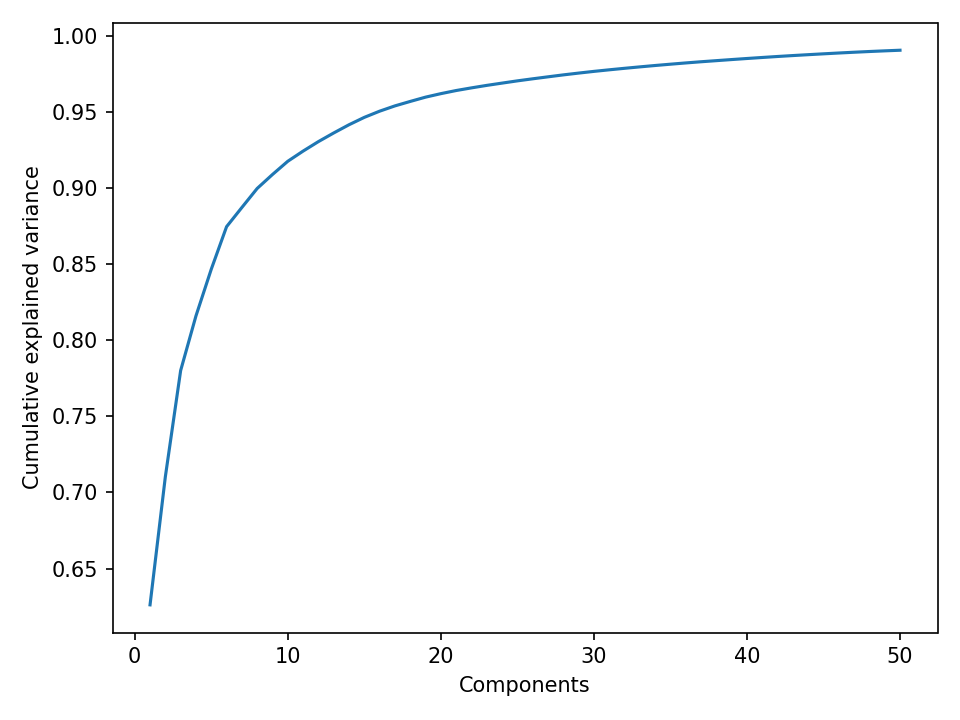

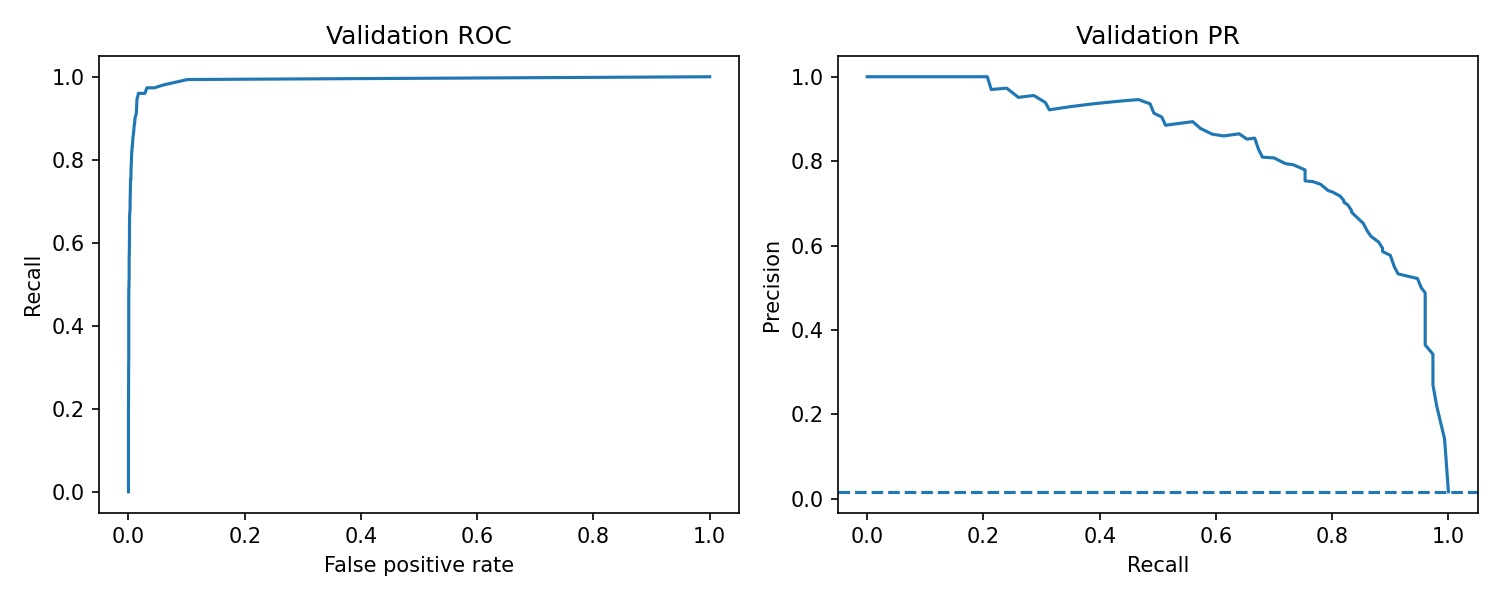

In [10]:
if REBUILD_EXPERIMENTS:
    run_module('experiments.py', ['--train', TRAIN, '--out', RESEARCH])
benchmarks = pd.read_csv(RESEARCH / 'validation_benchmarks.csv')
assert len(benchmarks) == 5 and np.isfinite(benchmarks['cost']).all()
display(benchmarks)
display(Image(filename=str(RESEARCH / 'pca.png')))
display(Image(filename=str(RESEARCH / 'roc_pr.png')))


## 10. Complexity analysis

Train/validation minority F1 versus depth illustrates generalization behavior.
A widening gap is evidence worth investigating, not an exact bias/variance
decomposition or proof of a universal best depth. Repeated folds/learning
curves and new external data remain useful next experiments.


,depth,train_f1,validation_f1
0,2,0.281223,0.274361
1,4,0.384972,0.376471
2,6,0.461282,0.443750
3,8,0.486502,0.449180
4,10,0.571915,0.499069
5,12,0.608255,0.535211
6,16,0.687728,0.561555
7,20,0.767148,0.595533
8,25,0.834151,0.623656


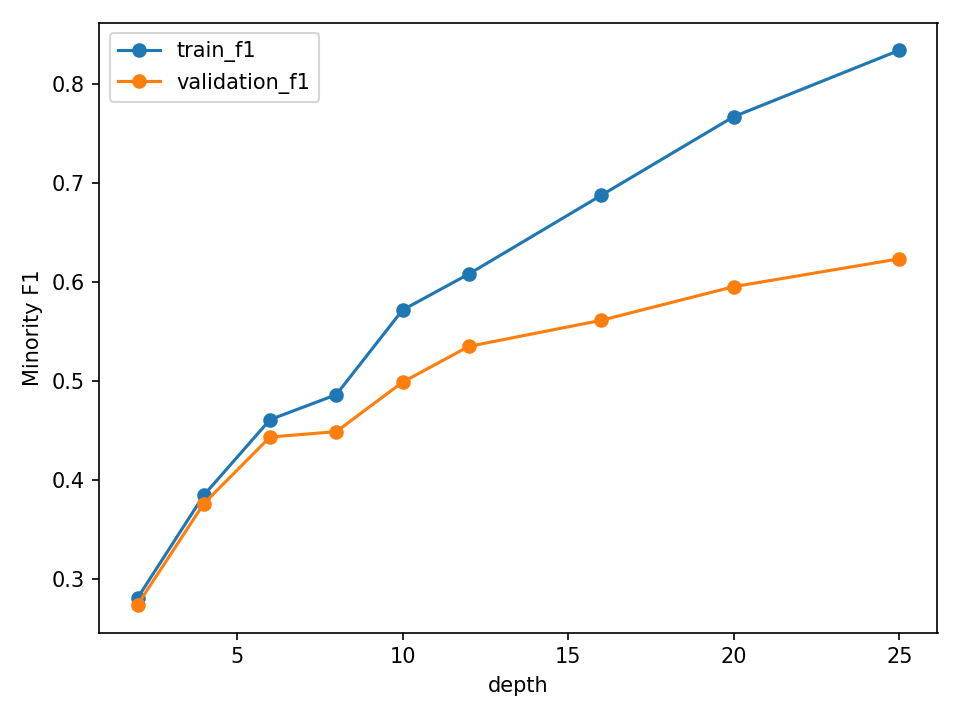

In [11]:
display(pd.read_csv(RESEARCH / 'complexity.csv'))
display(Image(filename=str(RESEARCH / 'complexity.png')))


## 11. Exploratory clustering and Ward linkage

PCA is fitted on the fit partition, then the fit-partition APS positives are
clustered. We report all k candidates and group sizes without attaching
invented mechanical diagnoses. Ward's plot uses a seeded subset of up to
250 failures. These groups do not predict named physical failure modes.


,k,silhouette,davies_bouldin,sizes
0,2,0.265256,1.560334,"[430, 420]"
1,3,0.272863,1.421912,"[161, 397, 292]"
2,4,0.303045,1.319889,"[154, 293, 83, 320]"


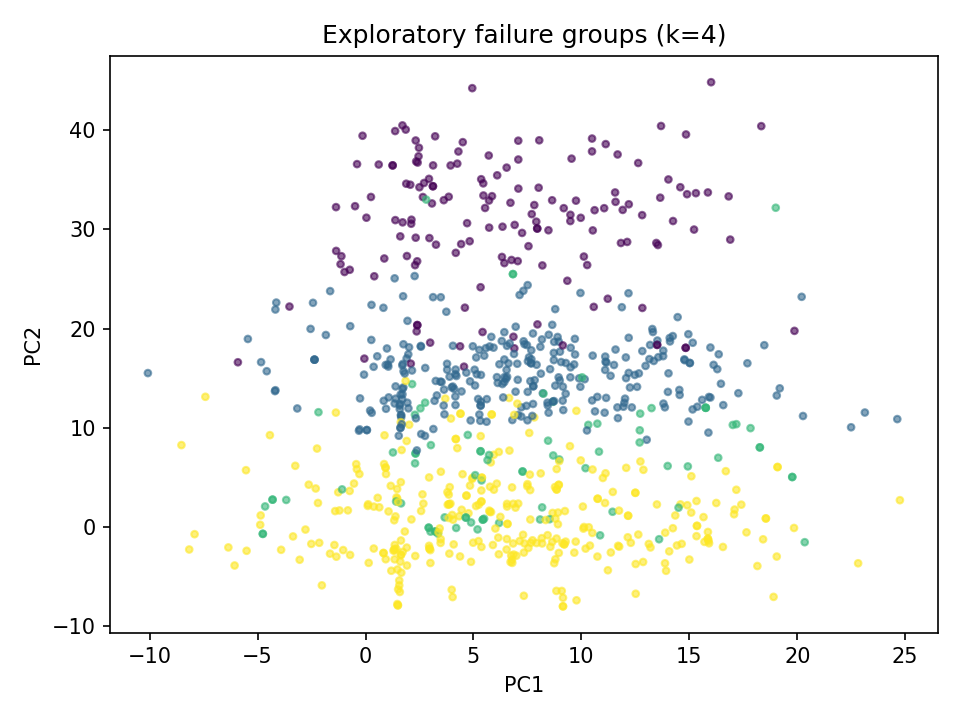

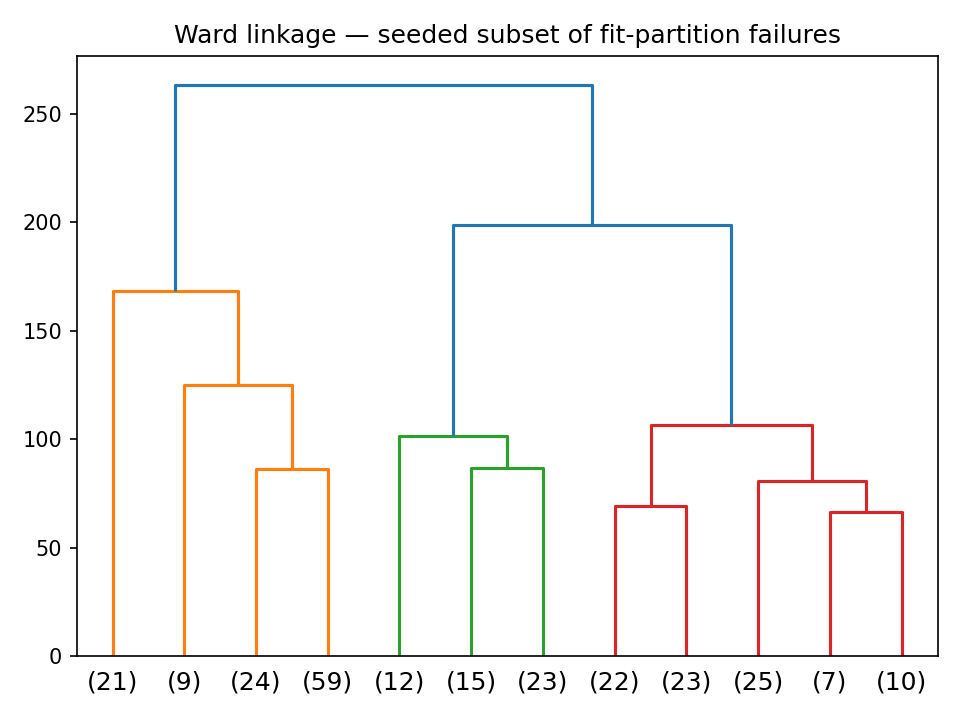

In [12]:
clusters = json.loads((RESEARCH / 'clusters.json').read_text())
display(pd.DataFrame(clusters))
display(Image(filename=str(RESEARCH / 'clusters.png')))
display(Image(filename=str(RESEARCH / 'dendrogram.png')))


## 12. The same raw-input path as the dashboard

The example CSV contains real training-set records, explicitly labeled as
examples. It is not an unseen benchmark or live fleet telemetry. `parse_upload`
and `score_batch` are the same functions used by the application.


In [13]:
payload = (ROOT / 'examples/aps_sample_input.csv').read_bytes()
raw_sample, sample_ids = parse_upload(payload, meta['raw_features'])
sample_results = score_batch(model, meta, raw_sample, sample_ids)
display(sample_results)
assert sample_results.model_score.between(0, 1).all()
print('Raw-CSV dashboard scoring path passed.')


,record_id,model_score,missing_fraction,action,model_id,threshold
0,training-example-1,0.00,0.029412,Below threshold,artifacts,0.11
1,training-example-2,0.00,0.123529,Below threshold,artifacts,0.11
2,training-example-3,0.00,0.047059,Below threshold,artifacts,0.11
3,training-example-4,0.88,0.100000,Review for inspection,artifacts,0.11
4,training-example-5,0.90,0.129412,Review for inspection,artifacts,0.11


Raw-CSV dashboard scoring path passed.


## 13. Full integration and final checks

Verification reloads this release, reproduces all test metrics, checks raw-CSV
parity and export, exercises concurrent calls, and times up to 10,000 records.
A notebook with successful execution is not a substitute for host login,
HTTPS, Docker and browser/mobile acceptance. Those remaining external checks
are listed in `docs/PROJECT_GUIDE.md`.


In [14]:
run_module('verify_release.py', ['--artifacts', RELEASE, '--test', TEST,
                              '--out', RUN / 'verification.json'])
integration = json.loads((RUN / 'verification.json').read_text())
assert integration['status'] == 'passed'
summary = {'run_id': RUN_ID, 'rebuilt_training': REBUILD_RELEASE,
           'rebuilt_research': REBUILD_EXPERIMENTS,
           'test_records': len(X_test), 'threshold': threshold,
           'test_cost': actual['cost'], 'verification': integration['status']}
(RUN / 'notebook-summary.json').write_text(json.dumps(summary, indent=2))
display(pd.Series(summary, name='executed_notebook'))
print('Notebook completed successfully. Approved application artifacts were not overwritten.')


{
  "status": "passed",
  "full_test_rows": 16000,
  "metrics": {
    "threshold": 0.11,
    "tn": 15393,
    "fp": 232,
    "fn": 28,
    "tp": 347,
    "cost": 16320,
    "roc_auc": 0.9933397333333334,
    "average_precision": 0.8817975028955924,
    "recall": 0.9253333333333333,
    "precision": 0.5993091537132987,
    "f1": 0.7274633123689728
  },
  "integration_checks": [
    "release integrity",
    "full-test metric reproduction",
    "raw CSV scoring parity",
    "CSV export",
    "four concurrent scoring calls",
    "10,000-row batch"
  ],
  "latency": {
    "1": {
      "csv_bytes": 2095,
      "median_ms": 29.97000000323169,
      "maximum_ms": 30.936499999370426,
      "repetitions": 3
    },
    "100": {
      "csv_bytes": 103176,
      "median_ms": 34.75179999804823,
      "maximum_ms": 70.02349999675062,
      "repetitions": 3
    },
    "1000": {
      "csv_bytes": 1040553,
      "median_ms": 95.29299999849172,
      "maximum_ms": 96.40590000344673,
      "repetitions":

run_id              20261114T145522Z-c46313
rebuilt_training                       True
rebuilt_research                       True
test_records                          16000
threshold                              0.11
test_cost                             16320
verification                         passed
Name: executed_notebook, dtype: object

Notebook completed successfully. Approved application artifacts were not overwritten.
